# 用 Transformer 搭一台 CPU

这台 16 位、4 寄存器、9 条指令的小 CPU **完全由一个 Transformer 实现**：权重是手工写入的，网络里只有 `nn.Linear`、ReLU、hardmax attention 和残差连接。

- 一次前向传播 = 执行一条指令；
- 外层循环只做 `x = model(x)`；
- 每一步的结果与普通 Python 参考 CPU **比特级一致**。

两种微架构：**v1**（6 个块，float64）和 **v2**（2 个块，投机执行 + 双端口内存，float32 也精确，可上 Apple GPU）。默认用 v2。

理论背景：Pérez et al.《Attention is Turing Complete》；Giannou et al. 2023《Looped Transformers as Programmable Computers》。

In [1]:
import torch, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from tfcpu import assemble, build_cpu, run, run_ref, encode, decode, LAYOUT
from tfcpu.state import CPU, PROG0, MEM0
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "PingFang SC", "Heiti TC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

model = build_cpu("v2", torch.float32)
L = model.layout
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nd_model = {L.d}, 序列长度 = 129 个 token, 参数量 = {n_params:,}")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


LoopedTransformer(
  (blocks): ModuleList(
    (0): Block(
      (attn): HardmaxAttention(
        (q): Linear(in_features=74, out_features=3, bias=False)
        (k): Linear(in_features=74, out_features=3, bias=False)
        (v): Linear(in_features=74, out_features=22, bias=False)
        (o): Linear(in_features=22, out_features=74, bias=False)
      )
      (mlp): MLP(
        (fc1): Linear(in_features=74, out_features=242, bias=True)
        (act): ReLU()
        (fc2): Linear(in_features=242, out_features=74, bias=True)
      )
    )
    (1): Block(
      (attn): HardmaxAttention(
        (q): Linear(in_features=74, out_features=12, bias=False)
        (k): Linear(in_features=74, out_features=12, bias=False)
        (v): Linear(in_features=74, out_features=6, bias=False)
        (o): Linear(in_features=6, out_features=74, bias=False)
      )
      (mlp): MLP(
        (fc1): Linear(in_features=74, out_features=117, bias=True)
        (act): ReLU()
        (fc2): Linear(in_features=

## 1. 跑一个冒泡排序

In [2]:
src = Path("../examples/bubble_sort.asm").read_text()
print(src)
prog = assemble(src)
trace = run(model, prog, max_steps=5000)
print("步数:", trace.steps, " 停机:", trace.final.halted)
print("排序前:", list(prog.mem[:8]))
print("排序后:", list(trace.final.mem[:8]))

; Bubble sort M[0..7] ascending. M[63] holds the outer pass counter (n - 1).
outer:  LOADI r0, 0          ; j = 0
inner:  LOAD  r1, r0, 0      ; x = M[j]
        LOAD  r2, r0, 1      ; y = M[j+1]
        SUB   r3, r2, r1     ; y - x
        JNEG  r3, swap       ; y < x  ->  swap
next:   LOADI r3, 1
        ADD   r0, r0, r3     ; j += 1
        LOADI r3, 7
        SUB   r3, r0, r3     ; j - 7
        JNEG  r3, inner
        LOAD  r1, r0, 56     ; j == 7 here, so this is M[63]
        LOADI r3, 1
        SUB   r1, r1, r3
        STORE r1, r0, 56
        JZ    r1, done
        JMP   outer
done:   HALT
swap:   STORE r2, r0, 0
        STORE r1, r0, 1
        JMP   next

.data 0  5 -3 12 0 7 7 -20 4
.data 63 7



步数: 535  停机: True
排序前: [5, -3, 12, 0, 7, 7, -20, 4]
排序后: [-20, -3, 0, 4, 5, 7, 7, 12]


## 2. 与参考 CPU 逐步对比

In [3]:
ref = run_ref(prog, max_steps=5000)
same = sum(a == b for a, b in zip(trace.states, ref))
print(f"{same} / {len(ref)} 个状态完全一致" + (" ✓" if trace.states == ref else " ✗"))

536 / 536 个状态完全一致 ✓


## 3. 权重长什么样

每个 MLP 隐藏单元都是一个 ReLU 积木（门控、判零、回绕……）。左图是 v2 的 B2（写回）第一层权重：行是隐藏单元，列是残差流里有名字的维度。颜色用 `sign(w)·log10(1+|w|)`，大常数 M = 2²⁰ 是门控用的。右图是 B2 的三个注意力头（读端口 + 两个写地址比较器）的 Wq/Wk。

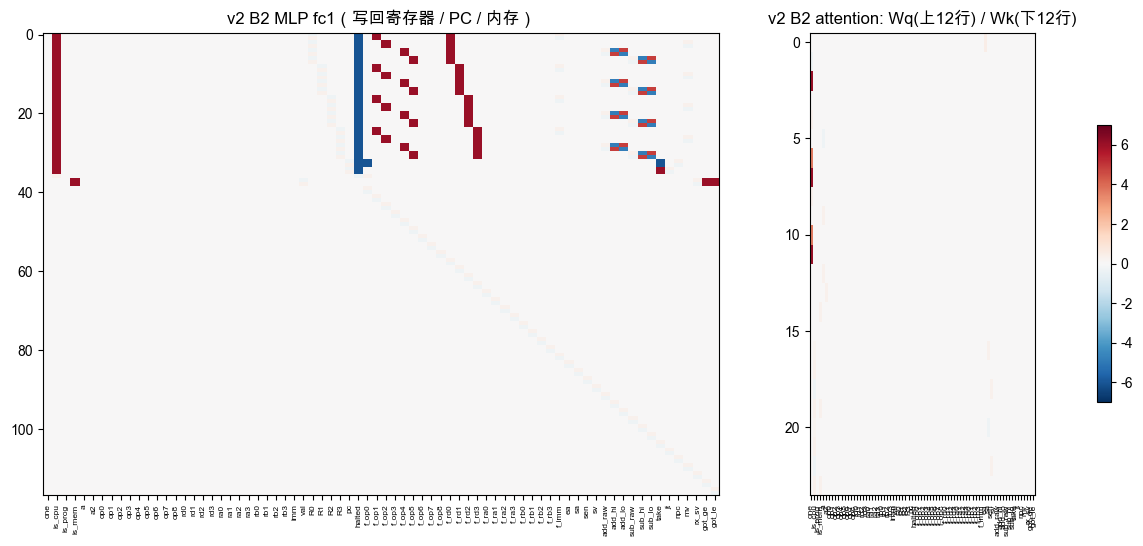

In [4]:
def show(W, xlabels, title, ax):
    W = W.numpy()
    im = ax.imshow(np.sign(W) * np.log10(1 + np.abs(W)), cmap="RdBu_r", vmin=-7, vmax=7, aspect="auto")
    ax.set_xticks(range(len(xlabels))); ax.set_xticklabels(xlabels, rotation=90, fontsize=6)
    ax.set_title(title); return im

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [3, 1]})
b2 = model.blocks[1]
im = show(b2.mlp.fc1.weight.double(), L.names, "v2 B2 MLP fc1（写回寄存器 / PC / 内存）", axes[0])
a2 = b2.attn
show(torch.cat([a2.q.weight, a2.k.weight]).double(), L.names, "v2 B2 attention: Wq(上12行) / Wk(下12行)", axes[1])
fig.colorbar(im, ax=axes, shrink=0.6); plt.show()

## 4. 看 attention 在做什么

取一条 STORE 指令执行前的状态，执行一次前向，记录 v2 的注意力：B1 里 CPU 取指、B2 头 1 里 CPU 读内存，hardmax 都恰好落在一个 token 上；B2 的两个写比较器头里，只有目标地址的内存 token 两个头都选中了 CPU。

第 5 步  PC = 17, 寄存器 = (0, 5, -3, -8)
B1 取指: CPU 注意力 100% 落在 token 18 = PROG[17] -> STORE r2, r0, 0
B2 写端口: 'sa >= a' 选中 CPU 的内存格 1 个, 'sa <= a' 64 个, 两者都选中的: MEM[0]
下一状态与参考一致: True


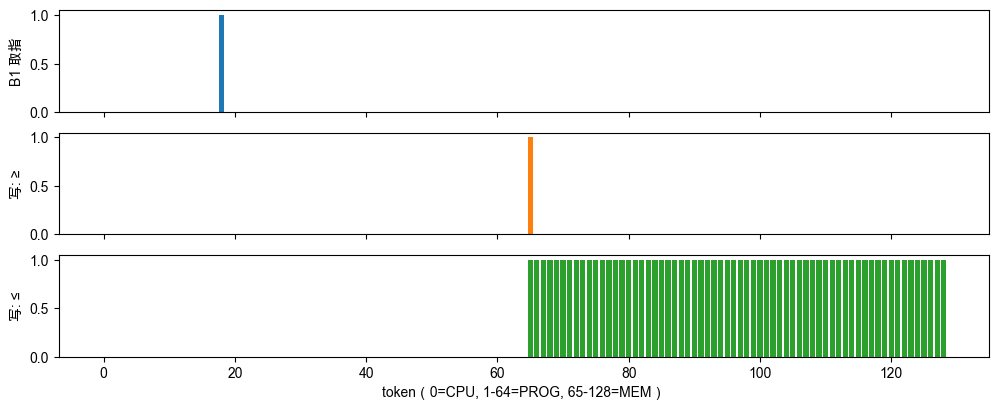

In [5]:
from tfcpu import Op
k = next(i for i, st in enumerate(trace.states) if not st.halted and st.program[st.pc].op == Op.STORE)
s = trace.states[k]
for blk in model.blocks: blk.attn.record = True
with torch.no_grad(): y = model(encode(s, L, torch.float32))
for blk in model.blocks: blk.attn.record = False

w_fetch = model.blocks[0].attn.last_weights[0, CPU]           # [head, query, key]
w_load = model.blocks[1].attn.last_weights[0, CPU]
w_ge = model.blocks[1].attn.last_weights[1, MEM0:MEM0 + 64, CPU]   # weight each MEM token puts on the CPU
w_le = model.blocks[1].attn.last_weights[2, MEM0:MEM0 + 64, CPU]
t1 = int(w_fetch.argmax())
target = [i for i in range(64) if w_ge[i] == 1 and w_le[i] == 1]
print(f"第 {k} 步  PC = {s.pc}, 寄存器 = {s.regs}")
print(f"B1 取指: CPU 注意力 100% 落在 token {t1} = PROG[{t1 - PROG0}] -> {s.program[t1 - PROG0]}")
print(f"B2 写端口: 'sa >= a' 选中 CPU 的内存格 {int(w_ge.sum())} 个, 'sa <= a' {int(w_le.sum())} 个, 两者都选中的: MEM{target}")
print("下一状态与参考一致:", decode(y, L) == trace.states[k + 1])

fig, ax = plt.subplots(3, 1, figsize=(12, 4.5), sharex=True)
ax[0].bar(range(129), w_fetch.numpy()); ax[0].set_ylabel("B1 取指")
ax[1].bar(range(MEM0, MEM0 + 64), w_ge.numpy(), color="C1", label="sa ≥ a"); ax[1].set_ylabel("写: ≥"); 
ax[2].bar(range(MEM0, MEM0 + 64), w_le.numpy(), color="C2", label="sa ≤ a"); ax[2].set_ylabel("写: ≤")
ax[2].set_xlabel("token（0=CPU, 1-64=PROG, 65-128=MEM）"); plt.show()

## 5. 寄存器和 PC 随时间变化

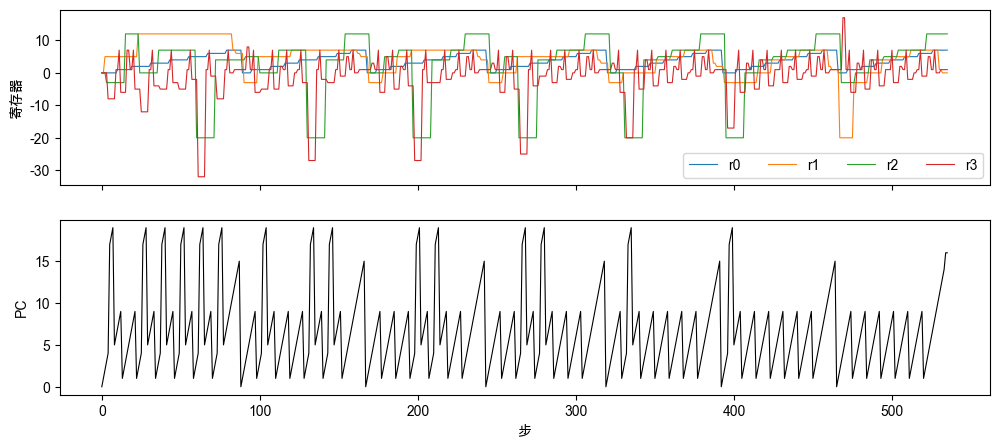

In [6]:
regs = np.array([st.regs for st in trace.states]); pcs = [st.pc for st in trace.states]
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
for i in range(4): ax[0].plot(regs[:, i], label=f"r{i}", lw=0.8)
ax[0].legend(ncol=4); ax[0].set_ylabel("寄存器")
ax[1].plot(pcs, lw=0.8, color="k"); ax[1].set_ylabel("PC"); ax[1].set_xlabel("步")
plt.show()

## 6. 微架构对比：v1 vs v2

v2 用投机执行（16 种寄存器组合的加减一次全算）、双端口内存（读端口 + 两个写地址比较器）把 6 个块压到 2 个，并把回绕拆到两层，使 float32 也精确。`FastCPU` 用同一套权重、只算会变的行（CPU + 被写的内存格），并缓存不变的 key/value。完整测速见 `bench.py`。

In [7]:
import time
from tfcpu.fast import run_fast
rows = []
for name, m in [("v1 float64", build_cpu("v1")), ("v2 float32", model)]:
    t0 = time.perf_counter(); tr = run(m, prog, 5000); dt = time.perf_counter() - t0
    rows.append((name, "完整模型 + 每步 decode", len(m.blocks), sum(p.numel() for p in m.parameters()), tr.steps / dt, tr.final == ref[-1]))
t0 = time.perf_counter(); fin = run_fast(model, prog, 5000); dt = time.perf_counter() - t0
rows.append(("v2 float32", "FastCPU", 2, n_params, (len(ref) - 1) / dt, fin == ref[-1]))
print(f"{'模型':<12}{'执行方式':<24}{'块数':>4}{'参数':>9}{'指令/秒':>10}  结果正确")
for r in rows: print(f"{r[0]:<12}{r[1]:<24}{r[2]:>4}{r[3]:>9,}{r[4]:>10,.0f}  {r[5]}")

模型          执行方式                      块数       参数      指令/秒  结果正确
v1 float64  完整模型 + 每步 decode           6   28,269       481  True
v2 float32  完整模型 + 每步 decode           2   60,003       516  True
v2 float32  FastCPU                    2   60,003     7,229  True


## 7. 写你自己的程序

指令：`LOADI rd, imm` · `LOAD rd, ra, imm` · `STORE rs, ra, imm` · `ADD/SUB rd, ra, rb` · `JZ/JNEG ra, label` · `JMP label` · `HALT`；`.data addr v1 v2 ...` 初始化内存。地址与跳转目标夹取到 0–63，算术 16 位回绕。

In [8]:
my = assemble('''
        LOADI r0, 30000
        LOADI r1, 10000
        ADD   r2, r0, r1     ; 40000 -> 回绕成 -25536
        STORE r2, r3, 0
        HALT
''')
t = run(model, my)
print(t.final.regs, t.final.mem[0], "| 参考一致:", t.states == run_ref(my))

(30000, 10000, -25536, 0) -25536 | 参考一致: True
